# PRODIGY_DS_02

## Data Cleaning and Exploratory Data Analysis (EDA)

### Titanic Passenger Dataset

**Internship:** Prodigy InfoTech

**Track:** Data Science

**Task:** 02



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (891, 15)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [8]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_data = missing_data[missing_data["Missing Values"] > 0]

missing_data

,Missing Values,Missing Percentage
age,177,19.865320
embarked,2,0.224467
deck,688,77.216611
embark_town,2,0.224467


In [9]:
# Create a copy of the original dataset
df_clean = df.copy()

# Drop deck column
df_clean.drop(columns=["deck"], inplace=True)

# Fill missing age values with median
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())

# Fill categorical missing values with mode
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])

df_clean["embark_town"] = df_clean["embark_town"].fillna(df_clean["embark_town"].mode()[0])

print("Data cleaning completed successfully!")

Data cleaning completed successfully!


In [10]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Cleaned dataset shape: (891, 14)


In [11]:
# Check duplicate records
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 116


In [12]:
# Statistical summary
df_clean.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [13]:
# Count survived and non-survived passengers
survival_counts = df_clean["survived"].value_counts()

print("Survival Counts:")
print(survival_counts)

print("\nSurvival Percentage:")
print(df_clean["survived"].value_counts(normalize=True) * 100)

Survival Counts:
survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


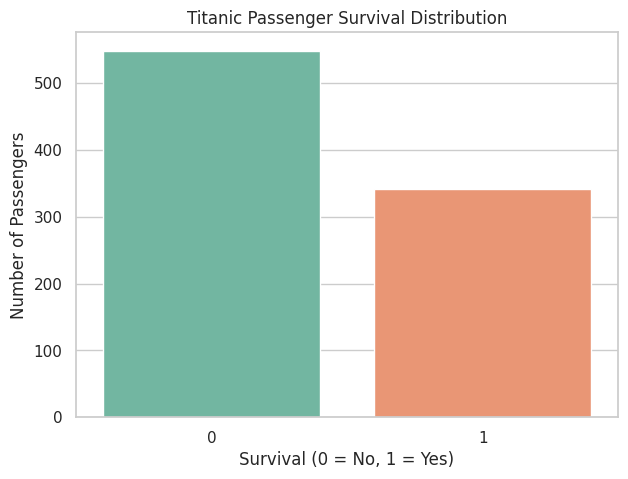

In [34]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="survived", hue="survived", palette="Set2", legend=False)

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.savefig("survival_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
gender_survival = pd.crosstab(
    df_clean["sex"],
    df_clean["survived"]
)

gender_survival.columns = ["Not Survived", "Survived"]

gender_survival

,Not Survived,Survived
sex,,
female,81,233
male,468,109


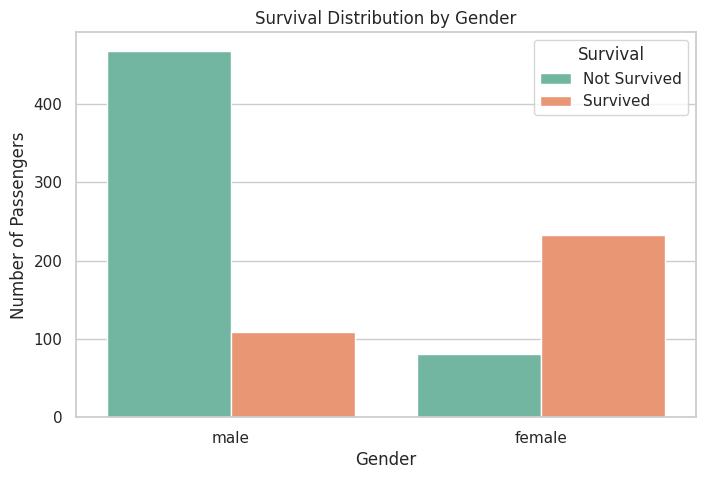

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="sex",
    hue="survived",
    palette="Set2"
)

plt.title("Survival Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survival", labels=["Not Survived", "Survived"])
plt.savefig("gender_survival.png", dpi=300, bbox_inches="tight")

plt.show()

In [17]:
# Calculate survival rate by gender
gender_survival_rate = df_clean.groupby("sex")["survived"].mean() * 100

print("Survival Rate by Gender:")
print(gender_survival_rate)

Survival Rate by Gender:
sex
female    74.203822
male      18.890815
Name: survived, dtype: float64


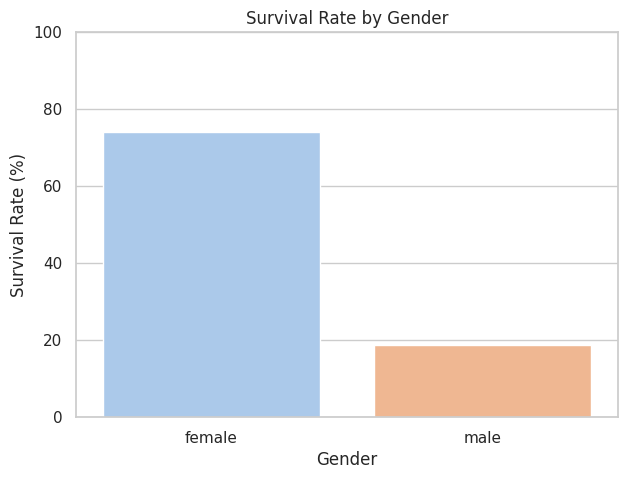

In [32]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_survival_rate.index,
    y=gender_survival_rate.values,
    hue=gender_survival_rate.index,
    palette="pastel",
    legend=False
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.savefig("gender_survival_rate.png", dpi=300, bbox_inches="tight")

plt.show()

In [19]:
# Survival count by passenger class
class_survival = pd.crosstab(
    df_clean["pclass"],
    df_clean["survived"]
)

class_survival.columns = ["Not Survived", "Survived"]

class_survival

,Not Survived,Survived
pclass,,
1,80,136
2,97,87
3,372,119


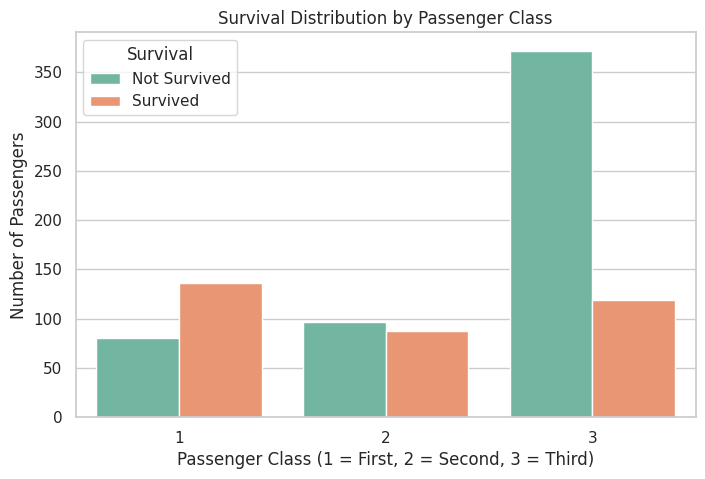

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="pclass",
    hue="survived",
    palette="Set2"
)

plt.title("Survival Distribution by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Number of Passengers")
plt.legend(title="Survival", labels=["Not Survived", "Survived"])

plt.savefig("class_survival.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
class_survival_rate = df_clean.groupby("pclass")["survived"].mean() * 100

print("Survival Rate by Passenger Class:")
print(class_survival_rate)

Survival Rate by Passenger Class:
pclass
1    62.962963
2    47.282609
3    24.236253
Name: survived, dtype: float64


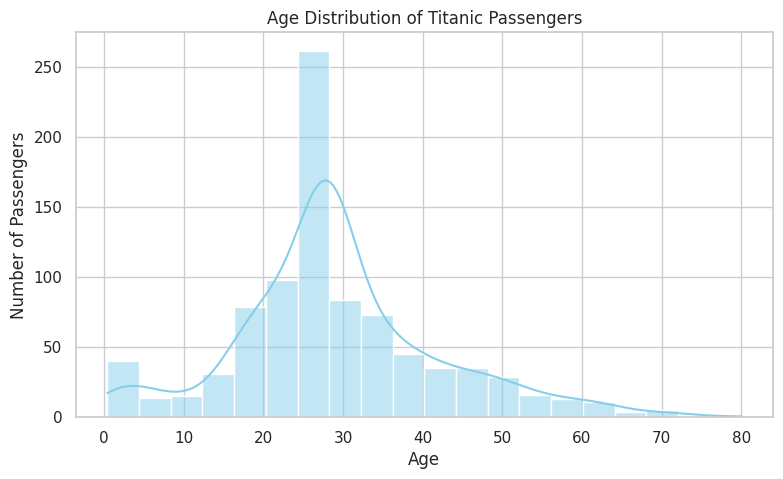

In [29]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="age",
    bins=20,
    kde=True,
    color="skyblue"
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.savefig("age_distribution_survival.png", dpi=300, bbox_inches="tight")

plt.show()

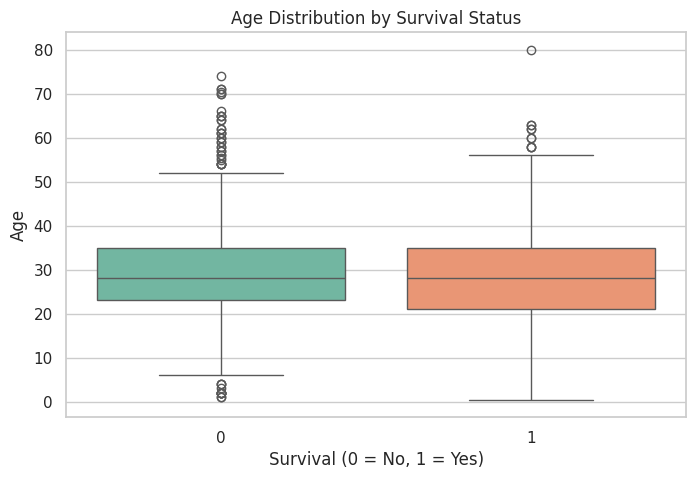

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="survived",
    y="age",
    hue="survived",
    palette="Set2",
    legend=False
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

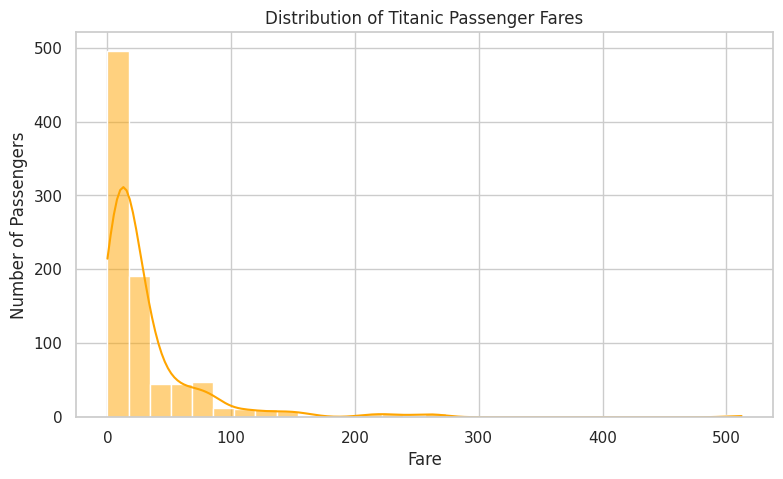

In [24]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="fare",
    bins=30,
    kde=True,
    color="orange"
)

plt.title("Distribution of Titanic Passenger Fares")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show()

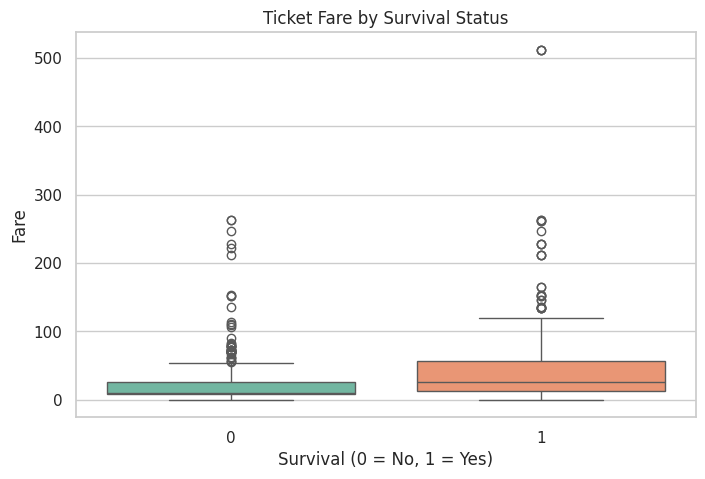

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="survived",
    y="fare",
    hue="survived",
    palette="Set2",
    legend=False
)

plt.title("Ticket Fare by Survival Status")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Fare")
plt.savefig("fare_survival.png", dpi=300, bbox_inches="tight")

plt.show()

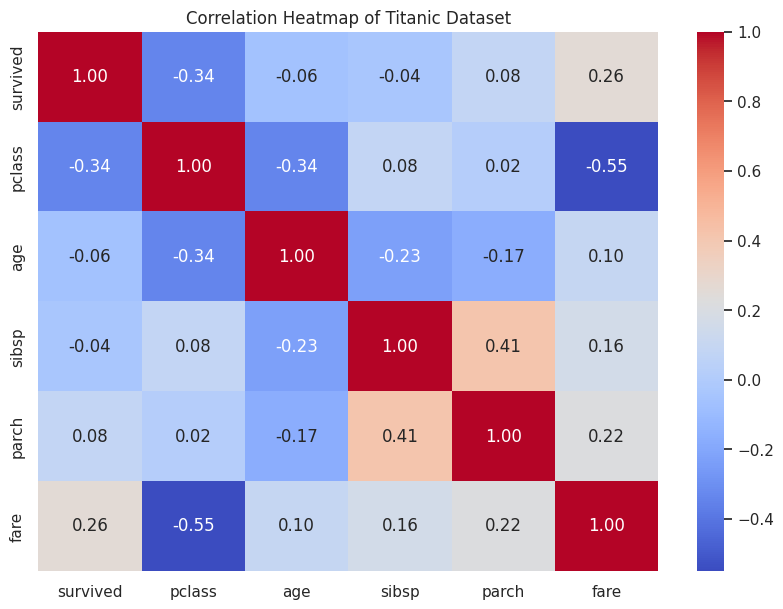

In [33]:
# Select numerical columns
numeric_data = df_clean.select_dtypes(include=["number"])

# Calculate correlation
correlation = numeric_data.corr()

# Display correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## Final Exploratory Data Analysis (EDA) Findings

### 1. Data Cleaning
- The original dataset contained 891 rows and 15 columns.
- Missing age values were filled using the median.
- Missing categorical values in `embarked` and `embark_town` were filled using the mode.
- The `deck` column was removed because approximately 77.22% of its values were missing.
- The cleaned dataset contains 891 rows and 14 columns with no missing values.

### 2. Overall Survival Analysis
- Total passengers: 891
- Passengers who survived: 342 (38.38%)
- Passengers who did not survive: 549 (61.62%)

### 3. Gender Analysis
- Female passengers had a considerably higher survival rate than male passengers.
- Female survival rate: approximately 74.20%.
- Male survival rate: approximately 18.89%.

### 4. Passenger Class Analysis
- First-class passengers had the highest survival rate (approximately 62.96%).
- Second-class passengers had a survival rate of approximately 47.28%.
- Third-class passengers had the lowest survival rate (approximately 24.24%).

### 5. Age Analysis
- The median age was approximately 28 years.
- Both survivors and non-survivors had similar median ages.
- The age distributions contained several outliers.

### 6. Fare Analysis
- Survivors generally had higher median ticket fares.
- The fare distribution contained several high-value outliers.
- Higher fares were associated with better survival outcomes.

### 7. Correlation Analysis
- Passenger class had a negative correlation with survival (-0.34).
- Fare had a positive correlation with survival (0.26).
- Age had a very weak correlation with survival (-0.06).

### Final Conclusion
The exploratory data analysis revealed meaningful patterns in the Titanic passenger dataset. Gender and passenger class showed notable differences in survival outcomes. Fare also showed a positive association with survival, while age had a very weak linear correlation.

This project provided practical experience in data cleaning, handling missing values, statistical analysis, data visualization, and exploratory data analysis using Python.

In [35]:
from google.colab import files
import zipfile

image_files = [
    "survival_distribution.png",
    "gender_survival.png",
    "gender_survival_rate.png",
    "class_survival.png",
    "age_distribution_survival.png",
    "fare_survival.png",
    "correlation_heatmap.png"
]

with zipfile.ZipFile("PRODIGY_DS_02_Charts.zip", "w") as zipf:
    for file in image_files:
        zipf.write(file)

files.download("PRODIGY_DS_02_Charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>